# Feasibility of the symbolic diagonalization of the Type I seesaw matrix

This notebook surveys all cases with up to three active and three sterile neutrinos and records, for each method, whether a closed form is obtained, how long it takes and how large it is. It is the summary of the series

| notebook | case |
|:--|:--|
| `seesaw_one_generation.ipynb`, `seesaw_one_generation_takagi.ipynb` | $(1,1)$ real / complex |
| `seesaw_2_active_1_sterile.ipynb`, `seesaw_3_active_1_sterile.ipynb` | $(2,1)$, $(3,1)$ |
| `seesaw_1_active_2_sterile.ipynb` | $(1,2)$ |
| `seesaw_2_active_2_sterile.ipynb`, `seesaw_3_active_2_sterile.ipynb`, `seesaw_1_active_3_sterile.ipynb` | quartic cases |
| `seesaw_3_active_3_sterile.ipynb` | $(2,3)$, $(3,3)$: no closed form |

**Setting.** $M=\begin{pmatrix}0&m_D\\m_D^T&M_R\end{pmatrix}$ with $n$ active and $m$ sterile states, $M_R=\mathrm{diag}(M_i)>0$, and $U^TMU=\mathrm{diag}(m_i)$. "Real": $m_D$ real. "Complex": $m_{Dij}=r_{ij}e^{i\phi_{ij}}$ with the $n$ unphysical phases removed.

**Methods.**

* `direct` — masses and $U$ as functions of $m_D$, $M_R$ (roots of the degree-$k$ characteristic polynomial, $k=m+\min(n,m)$).
* `semi_explicit` — $U$ as a function of $m_D$, $M_R$ *and* the masses, the latter constrained by the characteristic polynomial.
* `inverse` — $m_D$, $M_R$ and $U$ as functions of the masses and of an orthogonal matrix $O$ (exact Casas–Ibarra parametrization).
* `expansion` — block diagonalization to order $(m_D/M_R)^4$.

Each attempt runs in a subprocess with a time limit; `verified` is a numerical check of $U^TMU=\mathrm{diag}(m)$, unitarity and the masses at random points. Two sizes are recorded (see `expression_size`): `size`, the number of nodes of the result written out in full, and `dag_size`, the number of distinct subexpressions, i.e. the length of the result as a sequence of nested definitions. The measured object is $U$ for `direct` and `semi_explicit`, the full matrix $M$ for `inverse`, and $m_\nu$ for `expansion`.

In [1]:
import os
import sys

# Make the ``src`` package importable (the notebook lives in ``notebooks/``)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import sympy as sp
from sympy import (symbols, solve, sin, cos, tan, sqrt, exp, I, pi, Matrix,
                   conjugate, factor, simplify, init_printing)

from src.seesaw import SymbolicSeesawTypeI
from src.matrix_utils import (symbolic_rotation_matrix, sin_cos_from_tan_fraction,
                              simplify_with_mass_ordering, seesaw_block_expansion,
                              takagi_factorization)
from src.symbolic_diagonalization import *

init_printing()
import pandas as pd

TIMEOUT = 300   # seconds per attempt
cases = [(1, 1), (2, 1), (3, 1), (1, 2), (2, 2), (3, 2), (1, 3), (2, 3), (3, 3)]

## 1. Structure of each case

In [2]:
structure = pd.DataFrame([{
    '(n, m)': (n, m),
    'massless': max(n - m, 0),
    'massive k': m + min(n, m),
    'physical phases n(m-1)': n*(m - 1),
    'real parameters (m_D, M_R diag)': n*m + m,
    'masses in radicals': 'yes' if m + min(n, m) <= 4 else 'no',
} for n, m in cases]).set_index('(n, m)')
structure

,massless,massive k,physical phases n(m-1),"real parameters (m_D, M_R diag)",masses in radicals
"(n, m)",,,,,
"(1, 1)",0,2,0,2,yes
"(2, 1)",1,2,0,3,yes
"(3, 1)",2,2,0,4,yes
"(1, 2)",0,3,1,4,yes
"(2, 2)",0,4,2,6,yes
"(3, 2)",1,4,3,8,yes
"(1, 3)",0,4,2,6,yes
"(2, 3)",0,5,4,9,no
"(3, 3)",0,6,6,12,no


## 2. Survey

In [3]:
records = []
for method in ('direct', 'semi_explicit', 'inverse', 'expansion'):
    for cp in ('real', 'complex'):
        for n, m in cases:
            records.append(feasibility_probe(n, m, cp, method, timeout=TIMEOUT))
survey = pd.DataFrame(records)
survey['case'] = [f'({n},{m})' for n, m in zip(survey['n'], survey['m'])]
len(survey), survey['status'].value_counts().to_dict()

(72,
 {'ok': 68, 'no closed form (degree 5)': 2, 'no closed form (degree 6)': 2})

In [4]:
def pivot(column, cp):
    table = survey[survey['cp'] == cp].pivot(index='case', columns='method', values=column)
    return table.loc[[f'({n},{m})' for n, m in cases], ['direct', 'semi_explicit', 'inverse', 'expansion']]

### Real parameters

In [5]:
pivot('status', 'real')

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",ok,ok,ok,ok
"(2,1)",ok,ok,ok,ok
"(3,1)",ok,ok,ok,ok
"(1,2)",ok,ok,ok,ok
"(2,2)",ok,ok,ok,ok
"(3,2)",ok,ok,ok,ok
"(1,3)",ok,ok,ok,ok
"(2,3)",no closed form (degree 5),ok,ok,ok
"(3,3)",no closed form (degree 6),ok,ok,ok


Size written out in full, and as nested definitions:

In [6]:
pivot('size', 'real')

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",220.0,49.0,44.0,16.0
"(2,1)",821.0,175.0,49.0,132.0
"(3,1)",1664.0,391.0,56.0,366.0
"(1,2)",6834.0,396.0,1535.0,135.0
"(2,2)",508996.0,1680.0,251341.0,992.0
"(3,2)",3348926.0,9734.0,251350.0,3057.0
"(1,3)",640618.0,1851.0,6761.0,232.0
"(2,3)",NaN,15864.0,1544089.0,1714.0
"(3,3)",NaN,113742.0,453685613.0,5256.0


In [7]:
pivot('dag_size', 'real')

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",32.0,18.0,18.0,13.0
"(2,1)",50.0,36.0,18.0,20.0
"(3,1)",71.0,56.0,18.0,31.0
"(1,2)",114.0,51.0,68.0,38.0
"(2,2)",262.0,122.0,224.0,92.0
"(3,2)",552.0,385.0,224.0,180.0
"(1,3)",275.0,128.0,112.0,54.0
"(2,3)",NaN,508.0,362.0,137.0
"(3,3)",NaN,1932.0,821.0,251.0


In [8]:
pivot('seconds', 'real').round(1)

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",0.3,0.2,0.1,0.2
"(2,1)",1.1,0.6,0.2,0.2
"(3,1)",1.4,0.9,0.1,0.3
"(1,2)",0.4,0.1,0.2,0.2
"(2,2)",1.0,0.3,0.7,0.5
"(3,2)",4.7,2.2,0.8,0.6
"(1,3)",1.0,0.3,0.4,0.4
"(2,3)",0.1,1.6,1.3,0.7
"(3,3)",0.2,5.3,6.0,1.3


### Complex parameters

In [9]:
pivot('status', 'complex')

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",ok,ok,ok,ok
"(2,1)",ok,ok,ok,ok
"(3,1)",ok,ok,ok,ok
"(1,2)",ok,ok,ok,ok
"(2,2)",ok,ok,ok,ok
"(3,2)",ok,ok,ok,ok
"(1,3)",ok,ok,ok,ok
"(2,3)",no closed form (degree 5),ok,ok,ok
"(3,3)",no closed form (degree 6),ok,ok,ok


In [10]:
pivot('size', 'complex')

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",628.0,224.0,46.0,16.0
"(2,1)",6274.0,810.0,51.0,132.0
"(3,1)",19936.0,1792.0,58.0,366.0
"(1,2)",77226.0,4257.0,1653.0,168.0
"(2,2)",61152462.0,58788.0,323822.0,1314.0
"(3,2)",749399682.0,602880.0,323831.0,4173.0
"(1,3)",28015186.0,43828.0,7598.0,318.0
"(2,3)",NaN,889225.0,2422252.0,2534.0
"(3,3)",NaN,15776160.0,687781890.0,8046.0


In [11]:
pivot('dag_size', 'complex')

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",47.0,34.0,19.0,13.0
"(2,1)",74.0,56.0,19.0,20.0
"(3,1)",102.0,77.0,19.0,31.0
"(1,2)",194.0,118.0,71.0,46.0
"(2,2)",545.0,376.0,254.0,115.0
"(3,2)",1398.0,1047.0,254.0,223.0
"(1,3)",509.0,331.0,115.0,69.0
"(2,3)",NaN,1249.0,418.0,178.0
"(3,3)",NaN,4038.0,1159.0,324.0


In [12]:
pivot('seconds', 'complex').round(1)

method,direct,semi_explicit,inverse,expansion
case,,,,
"(1,1)",0.2,0.4,0.1,0.2
"(2,1)",0.7,0.9,0.2,0.2
"(3,1)",0.9,0.8,0.1,0.4
"(1,2)",0.7,0.5,0.2,0.6
"(2,2)",5.4,2.7,0.8,1.0
"(3,2)",22.2,17.4,0.9,1.7
"(1,3)",3.9,2.5,0.4,0.9
"(2,3)",4.5,11.3,1.2,1.4
"(3,3)",59.2,104.5,13.2,2.3


### Numerical verification

Every successful attempt (except the expansion, which is approximate by construction) must pass the numerical check.

In [13]:
checked = survey[(survey['status'] == 'ok') & (survey['method'] != 'expansion')]
len(checked), bool(checked['verified'].all())

(50, True)

## 3. Expression size versus number of massive states

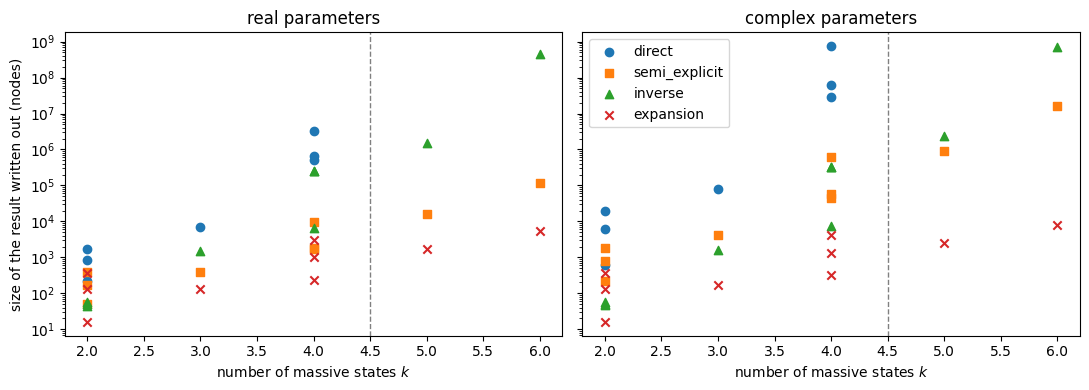

In [14]:
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)   # silence warnings from user style files
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, cp in zip(axes, ('real', 'complex')):
    for method, marker in (('direct', 'o'), ('semi_explicit', 's'), ('inverse', '^'), ('expansion', 'x')):
        data = survey[(survey['cp'] == cp) & (survey['method'] == method) & (survey['status'] == 'ok')]
        axis.scatter(data['degree'], data['size'].astype(float), marker=marker, label=method)
    axis.axvline(4.5, color='gray', linestyle='--', linewidth=1)
    axis.set_yscale('log')
    axis.set_xlabel('number of massive states $k$')
    axis.set_title(f'{cp} parameters')
axes[0].set_ylabel('size of the result written out (nodes)')
axes[1].legend()
fig.tight_layout()

The dashed line marks $k=4$: to its right the `direct` method has no points, because the characteristic polynomial is not solvable in radicals.

## 4. Conclusions

* **Direct diagonalization** works up to four massive states: $(n,1)$ for any $n$, $(1,2)$, $(2,2)$, $(3,2)$ and $(1,3)$. For $k\le2$ the results are compact; the cubic is manageable; the quartic is exact but too large to read when written out, although it remains short as a chain of nested definitions (`dag_size`) and is therefore cheap to evaluate numerically. For $(2,3)$ and $(3,3)$ no formula exists (Galois groups $S_5$, $S_6$).
* **Reductions.** For $n>m$ there are $n-m$ massless states and the problem reduces to $(m,m)$; in particular every $(n,1)$ case is the one-generation problem and has no physical phase.
* **Semi-explicit form.** The mixing matrix in terms of parameters and masses exists for every case and stays moderate in size.
* **Inverse problem.** $m_D$ and $M_R$ in terms of masses and an orthogonal matrix are available in closed form for every case in the table, including those where the direct problem is unsolvable, since only the square root of a $\min(n,m)$-dimensional matrix is needed.
* **Seesaw expansion.** Always available, and the light $3\times3$ sector can then be solved in closed form.